# 11 · Your first fit with Importance Sampling (IS)

**Level:** beginner · **Prerequisites:** none ([01](01_first_light_curve.ipynb) helps) · **Run time:** ~1 min (most of it the download)

**Covers:** downloading a TESS light curve with lightkurve, removing stellar variability with wotan, cutting out
the transits, fitting them with `MarginalTransitModel.fit()`, and a corner plot of the posterior

We fit a real planet: WASP-18 b, a massive hot Jupiter that transits its star every 0.94 days. TESS observed it
in 2018. The whole fit is one function call, `model.fit()`, which uses importance sampling instead of MCMC and
takes about a second. The limb darkening of the star is fitted too, without us having to sample it.

You need:

```bash
pip install "pizzetti[fit]" lightkurve wotan corner matplotlib
```

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # lightkurve warns about an optional package
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from wotan import flatten, transit_mask
import pizzetti

## Step 1: download the light curve

`lightkurve` finds and downloads the TESS light curve (sector 2, one point every 2 minutes). We remove missing
values and divide by the median, so that the flux is around 1.

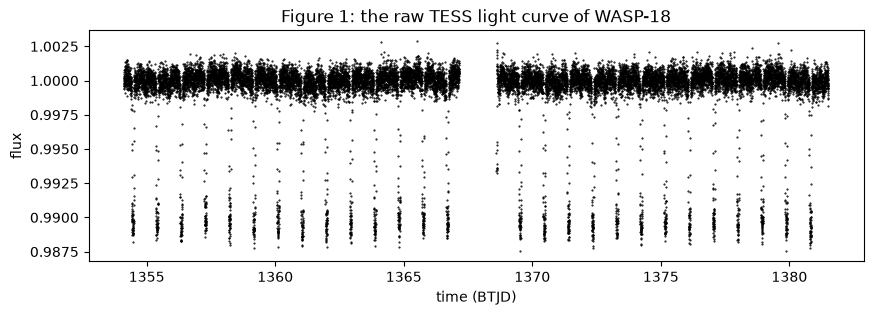

In [2]:
search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC", exptime=120, sector=2)
lc = search.download().remove_nans().normalize()
time = lc.time.value          # days (BTJD = BJD - 2457000)
flux = lc.flux.value

plt.figure(figsize=(10, 3))
plt.plot(time, flux, "k.", ms=1)
plt.xlabel("time (BTJD)"); plt.ylabel("flux")
plt.title("Figure 1: the raw TESS light curve of WASP-18");

The transits are the short dips, 1% deep. The slow wiggles come from the star and the instrument.

## Step 2: remove the slow variations with wotan

`flatten` fits a smooth trend (a robust running average over half a day) and divides it out. We tell it where the
transits are (`mask`), so that the trend is not pulled down by them. Period, mid-transit time and duration come
from the literature.

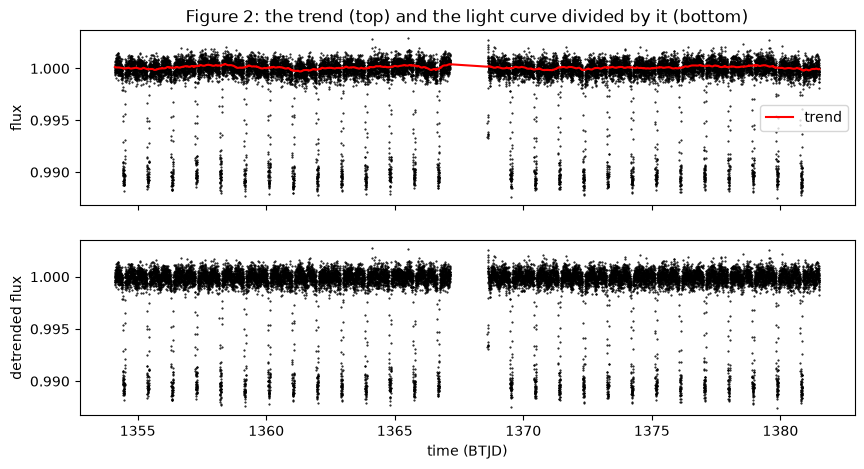

In [3]:
period = 0.94145223           # days
t0 = 1375.169883              # a mid-transit time (BTJD)
duration = 2.19 / 24          # days

mask = transit_mask(time=time, period=period, duration=1.5 * duration, T0=t0)
flat_flux, trend = flatten(time, flux, method="biweight", window_length=0.5, return_trend=True, mask=mask)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(time, flux, "k.", ms=1)
ax[0].plot(time, trend, "r", lw=1.5, label="trend")
ax[0].set_ylabel("flux"); ax[0].legend()
ax[0].set_title("Figure 2: the trend (top) and the light curve divided by it (bottom)")
ax[1].plot(time, flat_flux, "k.", ms=1)
ax[1].set_xlabel("time (BTJD)"); ax[1].set_ylabel("detrended flux");

## Step 3: keep the data around the transits

For the fit we only need the transits and a little flat light curve around them. We compute the phase (time from
the nearest mid-transit) and keep points within 0.15 days of a transit. The noise level comes from the points
outside the transits.

5804 points near the transits, noise 569 ppm per point


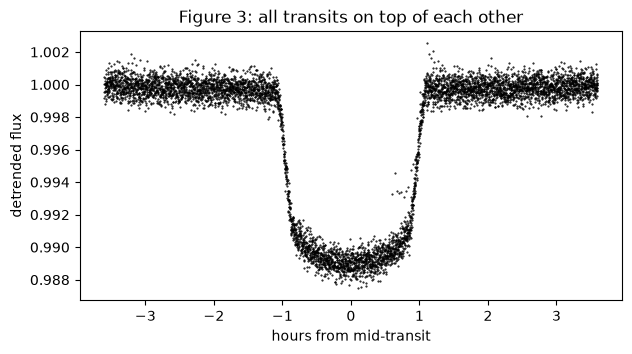

In [4]:
ok = np.isfinite(flat_flux)
time, flat_flux = time[ok], flat_flux[ok]
phase = (time - t0 + 0.5 * period) % period - 0.5 * period      # days from mid-transit
near = np.abs(phase) < 0.15
sigma = np.std(flat_flux[np.abs(phase) > duration])              # noise per point
print(f"{near.sum()} points near the transits, noise {sigma * 1e6:.0f} ppm per point")

plt.figure(figsize=(7, 3.5))
plt.plot(24 * phase[near], flat_flux[near], "k.", ms=1)
plt.xlabel("hours from mid-transit"); plt.ylabel("detrended flux")
plt.title("Figure 3: all transits on top of each other");

## Step 4: fit with importance sampling

`MarginalTransitModel` takes a first guess of the planet (`TransitParams`, as in batman), the times, the flux and
the noise. `free` lists the parameters to fit: the mid-transit time, the radius ratio Rp/R★, the scaled
semi-major axis a/R★ and the impact parameter b. The limb darkening and the flux level are fitted too, but
analytically, so they don't slow the fit down.

`model.fit()` returns a `FitResult`. `ld="u"` reports the limb darkening as the usual quadratic coefficients
u1 and u2.

In [5]:
params = pizzetti.TransitParams()
params.t0 = t0                    # first guesses
params.per = period
params.rp = 0.1
params.a = 3.5
params.inc = 84.0                 # degrees
params.ecc = 0.0
params.w = 90.0
params.limb_dark = "quadratic"
params.u = [0.4, 0.2]

model = pizzetti.MarginalTransitModel(params, time[near], flat_flux[near], sigma, free=["t0", "rp", "a", "b"])
result = model.fit(ld="u")
print(result.summary())

              median     -1sigma     +1sigma
t0           1375.17    3.16e-05    3.12e-05
rp        0.09859531     0.00035    0.000344
a           3.414583      0.0285        0.03
b          0.4139597      0.0229      0.0203
u1         0.3279826      0.0428      0.0455
u2         0.1203451       0.077      0.0813
f0         0.9998023    9.01e-06    8.73e-06


Every row is one parameter: its median and the distance to the 16% and 84% quantiles (the 1σ range). `f0` is the
flux outside the transit. Is the result reliable? `fit()` checks its own importance weights:

In [6]:
d = result.diagnostics
print(f"k-hat = {d['khat']:.2f}  (below 0.5 is good)")
print(f"effective number of draws = {d['ess']:.0f}")
print(f"passes its checks: {d['is_ok']}")

k-hat = -0.32  (below 0.5 is good)
effective number of draws = 3191
passes its checks: True


## Step 5: the model on the data

We take the median of every parameter and compute the light curve with pizzetti's `TransitModel`.

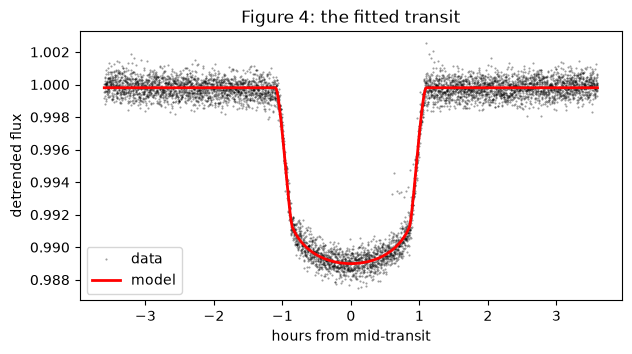

In [7]:
best = dict(zip(result.labels, np.median(result.samples, axis=0)))
params.t0, params.rp, params.a = best["t0"], best["rp"], best["a"]
params.inc = np.degrees(np.arccos(best["b"] / best["a"]))
params.u = [best["u1"], best["u2"]]

t_model = best["t0"] + np.linspace(-0.15, 0.15, 500)
f_model = best["f0"] * pizzetti.TransitModel(params, t_model).light_curve(params)

plt.figure(figsize=(7, 3.5))
plt.plot(24 * phase[near], flat_flux[near], "k.", ms=1, alpha=0.4, label="data")
plt.plot(24 * (t_model - best["t0"]), f_model, "r", lw=2, label="model")
plt.xlabel("hours from mid-transit"); plt.ylabel("detrended flux"); plt.legend()
plt.title("Figure 4: the fitted transit");

## Step 6: the corner plot

The corner plot shows every parameter's posterior (the histograms on the diagonal) and every pair of parameters
(the contours). `result.corner()` draws it from the weighted draws of importance sampling.

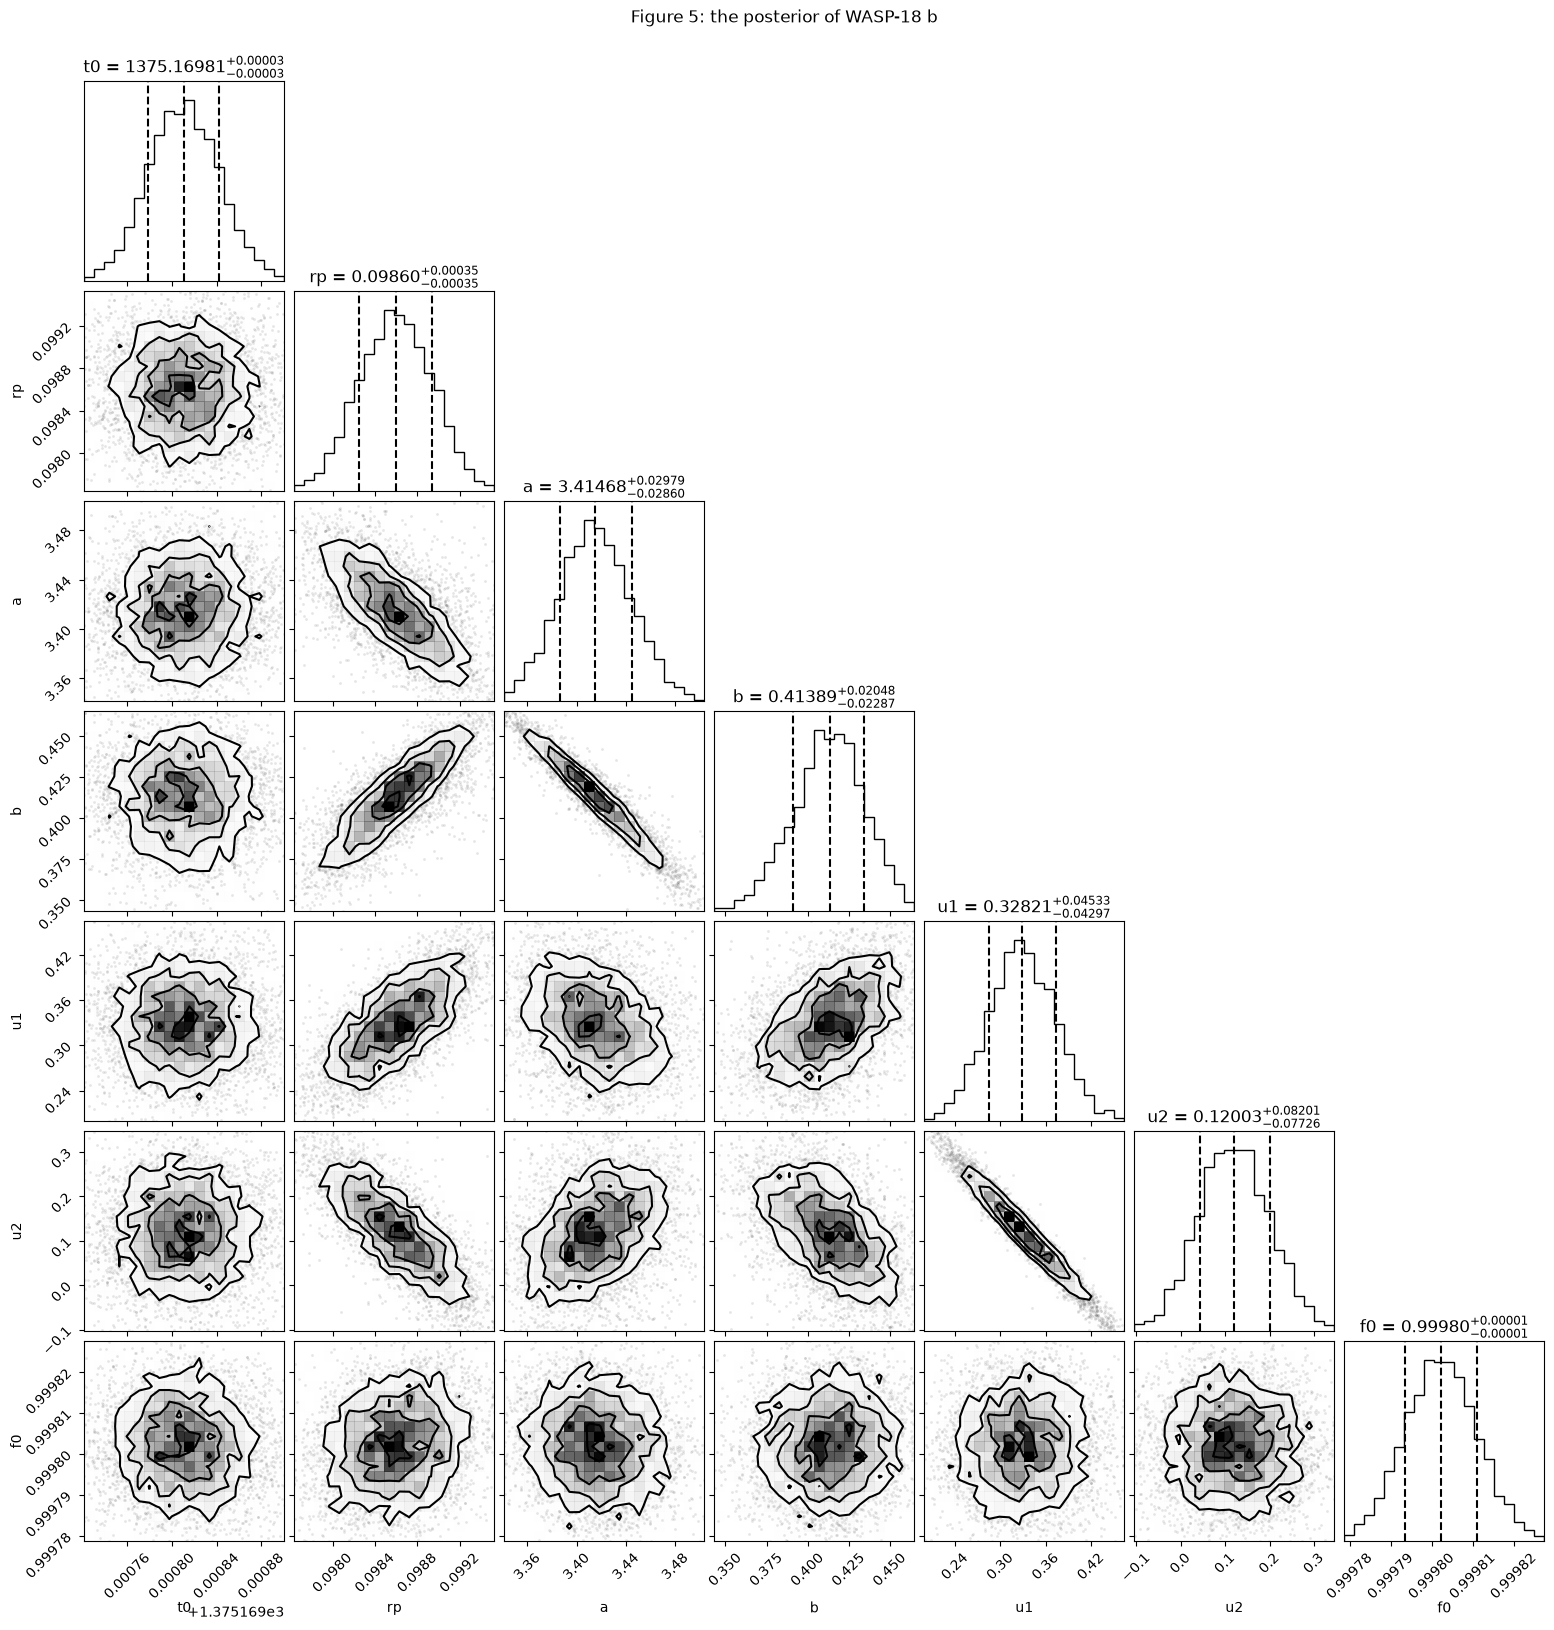

In [8]:
fig = result.corner(range=[0.995] * len(result.labels),   # each axis: the central 99.5% of the posterior
                    show_titles=True, title_fmt=".5f", quantiles=[0.16, 0.5, 0.84])
fig.suptitle("Figure 5: the posterior of WASP-18 b", y=1.02);

The radius ratio, a/R★ and b are correlated (a grazing-ish geometry with a closer orbit can mimic a more central
transit), and the limb-darkening coefficients u1 and u2 are strongly anticorrelated: the data constrain a
combination of them much better than each one alone. Importance sampling captures all of this without a single
MCMC step.

## What you learned

- Download (lightkurve), detrend (wotan), cut out the transits: three short steps.
- `MarginalTransitModel(...).fit()` fits the transit with importance sampling in about a second, limb darkening included.
- `result.summary()`, `result.diagnostics` and `result.corner()` show the result and whether to trust it.

**Next:** [12 · Importance sampling from scratch](12_importance_sampling_from_scratch.ipynb) explains how the
method works, and [17 · The Grand Tour](17_the_grand_tour.ipynb) finds a planet with TLS
before fitting it.